# 1. Welche Angaben hängen mit dem Überleben zusammen?

Unser Ziel ist, das Überleben der 418 Personen im Testdatensatz vorherzusagen. Zuerst suchen wir in den bekannten Daten nach Mustern: Unterscheiden sich die Überlebensquoten nach Geschlecht, Alter oder Ticketklasse?

Die Hauptanalyse folgt der Reihenfolge 00 → 01 → 02 → 03 → 04. Drei zusätzliche Notebooks erklären die einzelnen Modellarten genauer.


In [1]:
# Gestaltung der Abbildungen.
import json
from pathlib import Path
import matplotlib as mpl
import matplotlib.pyplot as plt
from cycler import cycler
from matplotlib import font_manager as fm
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap, to_rgb
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
COLORS = {'dk2': '#732124', 'lt2': '#F0EDE5', 'accent1': '#D34817', 'accent2': '#A68D65', 'accent3': '#728377', 'accent4': '#B4797B', 'accent5': '#CE8439', 'accent6': '#CF3A2A', 'hlink': '#D06853', 'folHlink': '#B67779'}
MAJOR_FONTS = ('Rockwell Nova Light', 'Rockwell Nova', 'Rockwell', 'DejaVu Serif')
MINOR_FONTS = ('Avenir Next LT Pro Light', 'Avenir Next LT Pro', 'Avenir Next', 'Calibri Light', 'Calibri', 'DejaVu Sans')
LEAF_CMAP = LinearSegmentedColormap.from_list('leaf', [COLORS['lt2'], COLORS['accent4'], COLORS['dk2']])
LEAF_CMAP.set_bad(COLORS['lt2'])

def resolved_fonts():
    available = {font.name for font in fm.fontManager.ttflist}
    major = next((name for name in MAJOR_FONTS if name in available))
    minor = next((name for name in MINOR_FONTS if name in available))
    return {'requested_heading': MAJOR_FONTS[0], 'heading': major, 'requested_body': MINOR_FONTS[0], 'body': minor, 'heading_file': fm.findfont(fm.FontProperties(family=major)), 'body_file': fm.findfont(fm.FontProperties(family=minor))}

def apply_leaf_theme():
    fonts = resolved_fonts()
    mpl.rcParams.update({'font.family': fonts['body'], 'font.size': 11, 'font.weight': 'normal', 'text.color': COLORS['dk2'], 'figure.facecolor': COLORS['lt2'], 'axes.facecolor': COLORS['lt2'], 'savefig.facecolor': COLORS['lt2'], 'savefig.transparent': False, 'axes.edgecolor': COLORS['accent2'], 'axes.linewidth': 0.7, 'axes.labelcolor': COLORS['dk2'], 'axes.labelsize': 11, 'axes.labelpad': 10, 'axes.titlesize': 13, 'axes.titleweight': 'normal', 'axes.titlepad': 14, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.axisbelow': True, 'axes.prop_cycle': cycler(color=[COLORS[f'accent{i}'] for i in range(1, 7)]), 'xtick.color': COLORS['dk2'], 'ytick.color': COLORS['dk2'], 'xtick.labelsize': 10, 'ytick.labelsize': 10, 'xtick.major.size': 0, 'ytick.major.size': 0, 'xtick.major.pad': 7, 'ytick.major.pad': 7, 'grid.color': COLORS['accent2'], 'grid.alpha': 0.22, 'grid.linewidth': 0.6, 'grid.linestyle': '-', 'legend.frameon': False, 'legend.fontsize': 10, 'lines.linewidth': 1.7, 'patch.linewidth': 0.8, 'boxplot.boxprops.color': COLORS['dk2'], 'boxplot.whiskerprops.color': COLORS['dk2'], 'boxplot.capprops.color': COLORS['dk2'], 'boxplot.medianprops.color': COLORS['dk2'], 'boxplot.flierprops.markeredgecolor': COLORS['dk2'], 'boxplot.flierprops.markerfacecolor': COLORS['lt2'], 'savefig.dpi': 300})
    return fonts

def _wrap_to_width(text, renderer, font_properties, max_width):
    lines = []
    for paragraph in text.split('\n'):
        line = ''
        for word in paragraph.split():
            candidate = f'{line} {word}'.strip()
            width = renderer.get_text_width_height_descent(candidate, font_properties, False)[0]
            if line and width > max_width:
                lines.append(line)
                line = word
            else:
                line = candidate
        lines.append(line)
    return '\n'.join(lines)

def decorate_leaf_figure(fig, number, title, note):
    fonts = resolved_fonts()
    heading = fm.FontProperties(family=fonts['heading'], size=17)
    body = fm.FontProperties(family=fonts['body'], size=9)
    fig.set_facecolor(COLORS['lt2'])
    fig.canvas.draw()
    renderer = fig.canvas.get_renderer()
    width_pixels, height_pixels = (fig.bbox.width, fig.bbox.height)
    for ax in fig.axes:
        ax.set_title(deutsch(ax.get_title()))
        ax.set_xlabel(deutsch(ax.get_xlabel()))
        ax.set_ylabel(deutsch(ax.get_ylabel()))
    title_text = _wrap_to_width(title, renderer, heading, 0.91 * width_pixels)
    note_text = _wrap_to_width('Anmerkung. ' + note, renderer, body, 0.91 * width_pixels)
    number_label = f'{number:02d}' if isinstance(number, int) else str(number)
    top_label = fig.text(0.045, 0.965, f'ABBILDUNG {number_label}', color=COLORS['accent1'], family=fonts['body'], fontsize=9, va='top')
    title_artist = fig.text(0.045, 0.91, title_text, fontproperties=heading, color=COLORS['dk2'], va='top', linespacing=1.12)
    note_artist = fig.text(0.045, 0.035, note_text, fontproperties=body, color=COLORS['dk2'], va='bottom', linespacing=1.3)
    fig.canvas.draw()
    title_box = title_artist.get_window_extent(renderer)
    note_box = note_artist.get_window_extent(renderer)
    top = title_box.y0 / height_pixels - 0.055
    bottom = note_box.y1 / height_pixels + 0.055
    if top - bottom < 0.28:
        raise ValueError('Figure is too short for its title/note; increase figsize height.')
    if fig.legends:
        for legend in fig.legends:
            for text in legend.get_texts():
                text.set_text(deutsch(text.get_text()))
            legend.set_loc('upper center')
            legend.set_bbox_to_anchor((0.5, top))
        fig.canvas.draw()
        top = min((legend.get_window_extent(renderer).y0 / height_pixels for legend in fig.legends)) - 0.035
    for ax in fig.axes:
        ax.set_title(deutsch(ax.get_title()))
        ax.set_xlabel(deutsch(ax.get_xlabel()))
        ax.set_ylabel(deutsch(ax.get_ylabel()))
        if ax.get_legend() is not None:
            for text in ax.get_legend().get_texts():
                text.set_text(deutsch(text.get_text()))
        ax.set_facecolor(COLORS['lt2'])
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        is_colorbar = hasattr(ax, '_colorbar')
        if ax.images or is_colorbar:
            ax.grid(False)
        elif ax.axison:
            horizontal = any((getattr(container, 'orientation', None) == 'horizontal' for container in ax.containers))
            horizontal = horizontal or 'fehlender' in ax.get_xlabel() or ax.get_xlabel() == 'Beobachtete Überlebensquote'
            ax.grid(axis='x' if horizontal else 'y')
        ax.title.set_fontfamily(fonts['heading'])
        ax.set_axisbelow(True)
    fig.add_artist(Line2D([0.045, 0.12], [top + 0.027, top + 0.027], transform=fig.transFigure, color=COLORS['accent1'], linewidth=2.5, solid_capstyle='butt'))
    fig.add_artist(Line2D([0.045, 0.955], [bottom - 0.022, bottom - 0.022], transform=fig.transFigure, color=COLORS['accent2'], linewidth=0.6, alpha=0.55))
    fig.tight_layout(rect=[0.025, bottom, 0.98, top], pad=1.1, w_pad=2.5)
    return (top_label, title_artist, note_artist)

def save_leaf_figure(fig, number, title, note, destination, *, show=True, dpi=None):
    destination = Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    decorate_leaf_figure(fig, number, deutsch(title), deutsch(note))
    fig.savefig(destination.with_suffix('.png'), dpi=dpi)
    if show:
        plt.show()
    plt.close(fig)

import pandas as pd
from IPython.display import display as _display

BEZEICHNUNGEN = {
    'Accuracy': 'Genauigkeit', 'CV-Accuracy': 'Mittlere Prüfgenauigkeit',
    'CV-F1': 'Mittlerer F1-Wert', 'CV-ROC AUC': 'Mittlere Fläche unter der Prüfkurve',
    'CV-Brier': 'Mittlerer Wahrscheinlichkeitsfehler', 'Fold-SD': 'Streuung der Prüfergebnisse',
    'Precision': 'Anteil richtiger Überlebensvorhersagen', 'Recall': 'Anteil erkannter Überlebender',
    'F1': 'F1-Wert', 'ROC AUC': 'Fläche unter der Prüfkurve',
    'Brier score': 'Wahrscheinlichkeitsfehler', "Cohen's kappa": 'Übereinstimmung über Zufallsniveau',
    'Feature': 'Merkmal', 'Coefficient': 'Gewicht', 'Feature importance': 'Merkmalsbedeutung',
    'Distance': 'Abstand', 'VoteWeight': 'Stimmgewicht', 'VoteShare': 'Stimmanteil',
    'Mean': 'Mittelwert', 'Standard deviation': 'Standardabweichung',
    '25% Quantile': 'Unteres Viertel', '75% Quantile': 'Oberes Viertel',
    'Binary target': 'Ergebnis mit zwei Werten', 'Ordinal category': 'Geordnete Kategorie',
    'Nominal category': 'Ungeordnete Kategorie', 'Candidate': 'Kombination',
    'Fold': 'Prüfdurchgang', 'Rank': 'Rang', 'Training': 'Genauigkeit in den Lerndaten',
    'Encoded columns': 'Anzahl aufbereiteter Merkmale',
    'Known holdout Accuracy': 'Genauigkeit im Kontrollvergleich',
    'Nested Personen Accuracy': 'Zusätzliche Prüfgenauigkeit (Personen)',
    'Nested Ticketgruppen Accuracy': 'Zusätzliche Prüfgenauigkeit (Ticketgruppen)',
    'Logistic Regression': 'Logistische Regression', 'Decision Tree': 'Entscheidungsbaum',
    'Shallow Decision Tree': 'Einfacher Entscheidungsbaum',
    'Extended Decision Tree': 'Erweiterter Entscheidungsbaum',
    'female': 'Weiblich', 'n_neighbors': 'Anzahl Nachbarn', 'p': 'Abstandsmaß', 'weights': 'Gewichtung', 'uniform': 'Gleichmäßig', 'distance': 'Nach Abstand', 'male': 'Männlich', 'Other': 'Sonstige',
    'Train': 'Trainingsdaten', 'Kaggle-Test': 'Testdaten',
}

def display(*werte):
    for wert in werte:
        if isinstance(wert, (pd.DataFrame, pd.Series)):
            wert = wert.copy()
            if isinstance(wert, pd.Series):
                wert = wert.to_frame()
            wert = wert.rename(columns=BEZEICHNUNGEN, index=BEZEICHNUNGEN)
            for spalte in wert.select_dtypes(include=['object', 'str']).columns:
                wert[spalte] = wert[spalte].replace(BEZEICHNUNGEN)
        if isinstance(wert, Markdown):
            wert = Markdown(deutsch(wert.data))
        _display(wert)


def deutsch(text):
    for vorher, nachher in {
        'Logistic Regression': 'Logistische Regression',
        'Shallow Decision Tree': 'Einfacher Entscheidungsbaum',
        'Extended Decision Tree': 'Erweiterter Entscheidungsbaum',
        'Decision Tree': 'Entscheidungsbaum',
        'Confusion Matrices': 'Richtige und falsche Vorhersagen',
        'Accuracy': 'Genauigkeit', 'Nested Personen-CV': 'zusätzlichen Personenprüfung',
        'Nested CV': 'zusätzliche Prüfung der Auswahl',
        'Outer fold': 'äußerer Prüfdurchgang', 'Auswahl-Folds': 'Prüfdurchgänge',
        'Training fold': 'Lerngruppe', 'Training folds': 'Lerngruppen',
        'Bekanntes Holdout': 'Kontrollvergleich', 'bekanntes Holdout': 'Kontrollvergleich', 'Holdout': 'Kontrolldatensatz',
        'Featuregruppe': 'Merkmalsgruppe', 'Feature': 'Merkmal',
        'Mean': 'Mittelwert', 'Target': 'Überleben',
        'standardized': 'bei gleicher Gruppenzusammensetzung',
        'Standardization': 'Angleichung der Gruppenzusammensetzung',
        'Median Imputation': 'Ergänzung mit dem mittleren Wert',
        'Labels': 'bekannte Ergebnisse', 'labels': 'bekannte Ergebnisse',
        'Log-Odds': 'Gewichte im Modell', 'Preprocessing': 'Datenvorbereitung',
        'Train:': 'Trainingsdaten:', 'Train (': 'Trainingsdaten (',
        'vollständigem Train': 'vollständigen Trainingsdaten',
        'nur Train': 'nur Trainingsdaten', '(Train)': '(Trainingsdaten)',
        'Nutzergrenzen nach Deckplänen': 'Vereinfachte Zuordnung',
        'keine testseitigen Überlebenslabels': 'Überleben der Testpersonen unbekannt',
        'Standardentscheidung': 'gewöhnliche Entscheidungsregel',
        'getunte Auswahlwerte sind optimistisch': 'die besten Auswahlwerte können zu günstig ausfallen',
        'CV': 'Kreuzvalidierung', 'Folds': 'Prüfgruppen',
        'female': 'weiblich', 'male': 'männlich',
    }.items():
        text = text.replace(vorher, nachher)
    return text




In [2]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import Markdown
import sklearn
pd.set_option('display.precision', 3)
Path('ergebnisse').mkdir(exist_ok=True)



## Datenbasis

Für 891 Personen ist bekannt, ob sie überlebt haben. Diese Personen verwenden wir hier vollständig. Für die 418 Personen in `test.csv` ist das tatsächliche Überleben unbekannt.

Eine hohe vorhergesagte Überlebensquote bedeutet nicht automatisch gute Vorhersagen: Dafür müsste man wissen, welche Vorhersagen tatsächlich richtig sind.


In [3]:
train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')
analyse = train.copy()
assert len(analyse) == 891 and analyse.PassengerId.is_unique
print(deutsch(f'Trainingsdaten: {len(train)}; Testdaten: {len(test)}'))
print(deutsch(f'Exploration mit allen {len(analyse)} Trainingspersonen; Aufteilung erst in Notebook 3.'))
print(deutsch(f'Beobachtete Überlebensquote im Trainingsdatensatz: {analyse.Survived.mean():.1%}'))
display(analyse.head())



Trainingsdaten: 891; Testdaten: 418
Exploration mit allen 891 Trainingspersonen; Aufteilung erst in Notebook 3.
Beobachtete Überlebensquote im Trainingsdatensatz: 38.4%


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",Männlich,22.0,1,0,A/5 21171,7.250,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",Weiblich,38.0,1,0,PC 17599,71.283,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",Weiblich,26.0,0,0,STON/O2. 3101282,7.925,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",Weiblich,35.0,1,0,113803,53.100,C123,S
4,5,0,3,"Allen, Mr. William Henry",Männlich,35.0,0,0,373450,8.050,NaN,S


## Welche Informationen stehen zur Verfügung?

| Spalte | Bedeutung |
|---|---|
| `PassengerId` | Nummer zur Zuordnung der Person |
| `Survived` | 0 = nicht überlebt, 1 = überlebt |
| `Pclass` | Ticketklasse 1, 2 oder 3 |
| `Sex`, `Age` | Erfasstes Geschlecht und Alter |
| `SibSp`, `Parch` | Erfasste Geschwister/Ehepartner und Eltern/Kinder |
| `Fare` | Erfasster Fahrpreis |
| `Embarked` | Einstiegsort |
| `Name`, `Ticket`, `Cabin` | Name, Ticketnummer und Kabine |

Die Daten enthalten nur einen Teil der Menschen an Bord.


In [4]:
fehlend = pd.DataFrame({'Fehlend Train (n)': analyse.isna().sum(), 'Fehlend Train (%)': 100 * analyse.isna().mean(), 'Fehlend Testdaten (n)': test.isna().sum(), 'Fehlend Testdaten (%)': 100 * test.isna().mean()}).drop(index='Survived')
display(fehlend)
display(analyse[['Age', 'Fare', 'SibSp', 'Parch']].describe())
print(deutsch('Doppelte vollständige Zeilen im vollständigen Trainingsdatensatz:'), analyse.duplicated().sum())
print(deutsch('Kennungen im vollständigen Trainingsdatensatz eindeutig:'), analyse.PassengerId.is_unique)
print(deutsch('Gemeinsame Kennungen von train und test:'), len(set(train.PassengerId) & set(test.PassengerId)))



,Fehlend Train (n),Fehlend Train (%),Fehlend Testdaten (n),Fehlend Testdaten (%)
Age,177,19.865,86.0,20.574
Cabin,687,77.104,327.0,78.230
Embarked,2,0.224,0.0,0.000
Fare,0,0.000,1.0,0.239
Name,0,0.000,0.0,0.000
Parch,0,0.000,0.0,0.000
PassengerId,0,0.000,0.0,0.000
Pclass,0,0.000,0.0,0.000
Sex,0,0.000,0.0,0.000
SibSp,0,0.000,0.0,0.000


,Age,Fare,SibSp,Parch
count,714.000,891.000,891.000,891.000
mean,29.699,32.204,0.523,0.382
std,14.526,49.693,1.103,0.806
min,0.420,0.000,0.000,0.000
25%,20.125,7.910,0.000,0.000
50%,28.000,14.454,0.000,0.000
75%,38.000,31.000,1.000,0.000
max,80.000,512.329,8.000,6.000


Doppelte vollständige Zeilen im vollständigen Trainingsdatensatz: 0
Kennungen im vollständigen Trainingsdatensatz eindeutig: True
Gemeinsame Kennungen von train und test: 0


## Überlebensquoten vergleichen

Die Grafiken zeigen Anteile überlebender Personen in den bekannten Daten. Die Linien um einen Punkt zeigen, wie unsicher eine Quote ist. Bei kleinen Gruppen sind diese Bereiche meist breiter.

Ein beobachteter Unterschied belegt noch keine Ursache. Gruppen können sich auch in anderen Eigenschaften unterscheiden.


In [5]:
ABBILDUNGEN = Path('abbildungen/01_exploration')
ABBILDUNGEN.mkdir(parents=True, exist_ok=True)
apply_leaf_theme()
PRIMAER, SEKUNDAER, FEHLEND = (COLORS['accent1'], COLORS['accent3'], COLORS['accent2'])

def abbildung(fig, nummer, titel, anmerkung, dateiname):
    save_leaf_figure(fig, nummer, titel, anmerkung, ABBILDUNGEN / dateiname)

def wilson_intervall(erfolge, n):
    anteil = erfolge / n
    nenner = 1 + 1.96 ** 2 / n
    mitte = (anteil + 1.96 ** 2 / (2 * n)) / nenner
    breite = 1.96 * np.sqrt(anteil * (1 - anteil) / n + 1.96 ** 2 / (4 * n ** 2)) / nenner
    return (mitte - breite, mitte + breite)



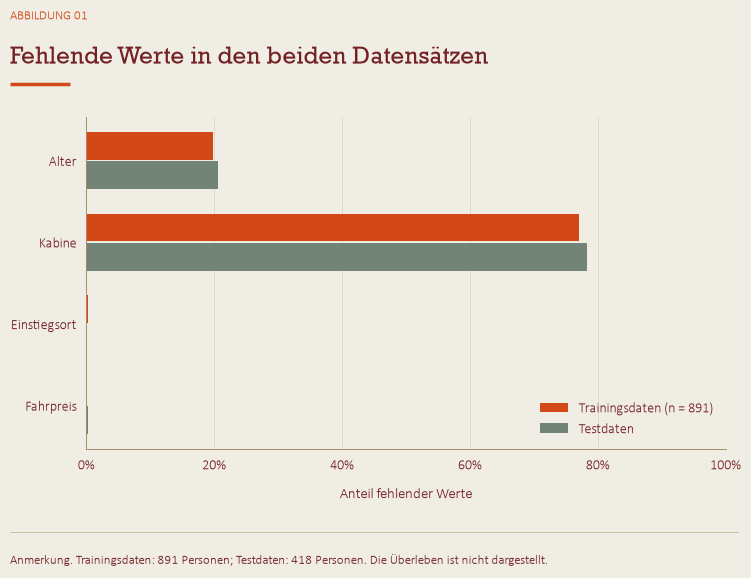

In [6]:
spalten = ['Age', 'Cabin', 'Embarked', 'Fare']
positionen = np.arange(4)
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(positionen - 0.18, analyse[spalten].isna().mean(), height=0.34, color=PRIMAER, label='Train (n = 891)')
ax.barh(positionen + 0.18, test[spalten].isna().mean(), height=0.34, color=SEKUNDAER, label='Testdaten')
ax.set(yticks=positionen, yticklabels=['Alter', 'Kabine', 'Einstiegsort', 'Fahrpreis'], xlabel='Anteil fehlender Werte', xlim=(0, 1))
ax.invert_yaxis()
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.legend(loc='lower right')
abbildung(fig, 1, 'Fehlende Werte in den beiden Datensätzen', 'Train: 891 Personen; Testdaten: 418 Personen. Die Target ist nicht dargestellt.', '01_fehlende_werte')



Überlebende  Personen  Quote  unten   oben
Sex      Pclass                                            
Weiblich 1                91        94  0.968  0.910  0.989
         2                70        76  0.921  0.838  0.963
         3                72       144  0.500  0.419  0.581
Männlich 1                45       122  0.369  0.288  0.457
         2                17       108  0.157  0.101  0.238
         3                47       347  0.135  0.103  0.175

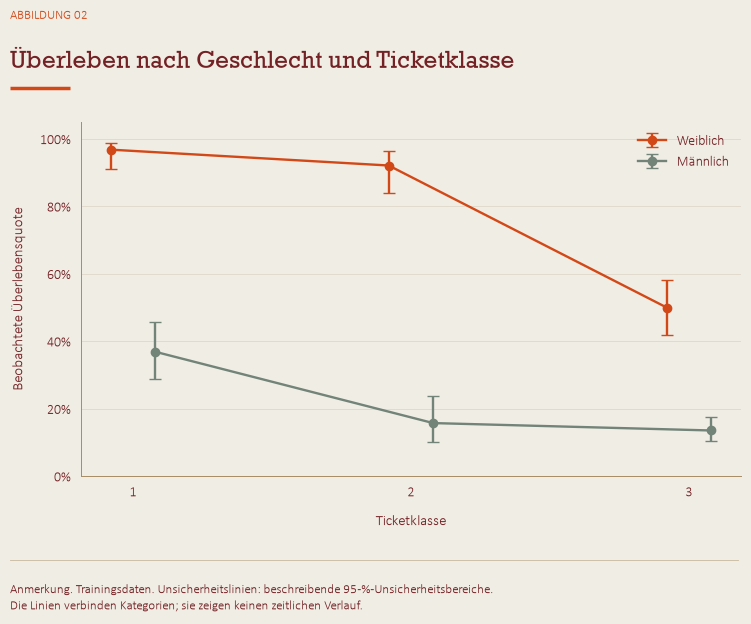

In [7]:
quoten = analyse.groupby(['Sex', 'Pclass']).Survived.agg(['sum', 'count', 'mean'])
quoten['unten'], quoten['oben'] = wilson_intervall(quoten['sum'], quoten['count'])
display(quoten.rename(columns={'sum': 'Überlebende', 'count': 'Personen', 'mean': 'Quote'}))
fig, ax = plt.subplots(figsize=(8, 6.5))
for geschlecht, versatz, farbe, text in [('female', -0.08, PRIMAER, 'Weiblich'), ('male', 0.08, SEKUNDAER, 'Männlich')]:
    gruppe = quoten.loc[geschlecht]
    ax.errorbar(gruppe.index + versatz, gruppe['mean'], yerr=[gruppe['mean'] - gruppe.unten, gruppe.oben - gruppe['mean']], fmt='o-', capsize=4, color=farbe, label=text)
ax.set(xticks=[1, 2, 3], xlabel='Ticketklasse', ylabel='Beobachtete Überlebensquote', ylim=(0, 1.05))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend(loc='upper right')
abbildung(fig, 2, 'Überleben nach Geschlecht und Ticketklasse', 'Trainingsdaten. Unsicherheitslinien: beschreibende 95-%-Unsicherheitsbereiche.\nDie Linien verbinden Kategorien; sie zeigen keinen zeitlichen Verlauf.', '02_geschlecht_ticketklasse')



### Überleben nach Geschlecht und Deck

Wir verwenden nur Personen, deren Kabinenangabe einem Deck von A bis G zugeordnet werden kann. Unter jedem Deck steht die Gruppengröße für Frauen und Männer.

Bei sehr kleinen Gruppen sollten Unterschiede vorsichtig interpretiert werden.


Überlebende  Personen  Quote  95% unten  95% oben
Sex      Kabinendeck                                                   
Weiblich A                      1         1  1.000      0.207     1.000
         B                     27        27  1.000      0.875     1.000
         C                     24        27  0.889      0.719     0.961
         D                     18        18  1.000      0.824     1.000
         E                     14        15  0.933      0.702     0.988
         F                      5         5  1.000      0.566     1.000
         G                      2         4  0.500      0.150     0.850
Männlich A                      6        14  0.429      0.214     0.674
         B                      8        20  0.400      0.219     0.613
         C                     11        32  0.344      0.204     0.517
         D                      7        15  0.467      0.248     0.699
         E                     10        17  0.588      0.360     0.784
         F                      3         8  0.375      0.137     0.694

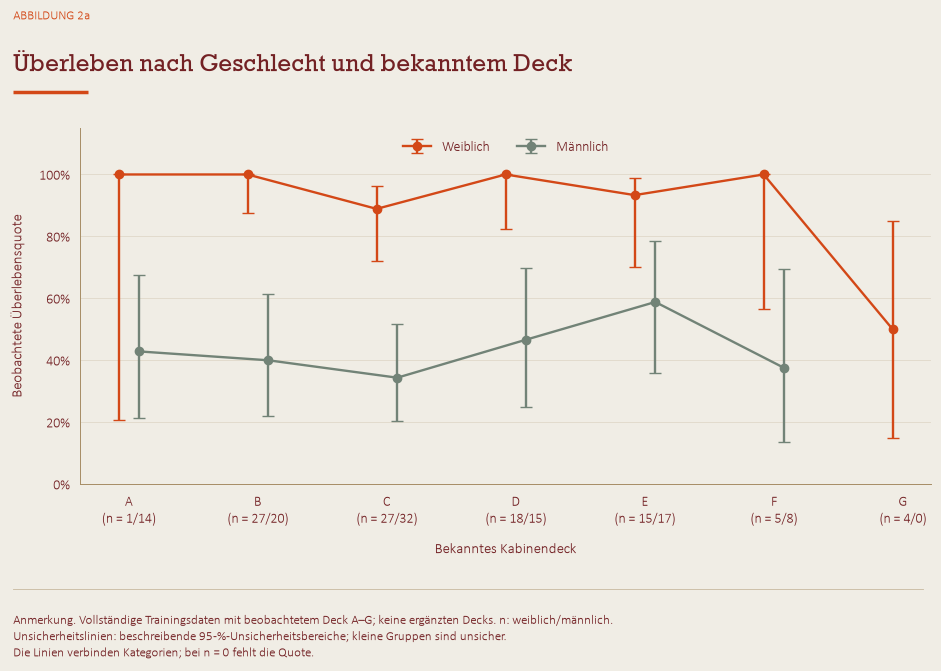

In [8]:
import re

def bekanntes_deck(kabine):
    if pd.isna(kabine):
        return np.nan
    text = kabine.strip().upper()
    if re.fullmatch('F [EG]\\d+', text):
        return 'F'
    teile = [re.fullmatch('([A-G])(\\d*)', teil) for teil in text.split()]
    if not teile or any((teil is None for teil in teile)):
        return np.nan
    decks = {teil[1] for teil in teile}
    return decks.pop() if len(decks) == 1 else np.nan
analyse_deck = analyse.assign(Kabinendeck=analyse.Cabin.map(bekanntes_deck))
quoten_deck = analyse_deck.dropna(subset=['Kabinendeck']).groupby(['Sex', 'Kabinendeck']).Survived.agg(['sum', 'count', 'mean'])
quoten_deck['unten'], quoten_deck['oben'] = wilson_intervall(quoten_deck['sum'], quoten_deck['count'])
display(quoten_deck.rename(columns={'sum': 'Überlebende', 'count': 'Personen', 'mean': 'Quote', 'unten': '95% unten', 'oben': '95% oben'}))
decks = list('ABCDEFG')
positionen = np.arange(len(decks))
fig, ax = plt.subplots(figsize=(10, 7))
for geschlecht, versatz, farbe, text in [('female', -0.08, PRIMAER, 'Weiblich'), ('male', 0.08, SEKUNDAER, 'Männlich')]:
    gruppe = quoten_deck.loc[geschlecht].reindex(decks)
    ax.errorbar(positionen + versatz, gruppe['mean'], yerr=[gruppe['mean'] - gruppe.unten, gruppe.oben - gruppe['mean']], fmt='o-', capsize=4, color=farbe, label=text)
anzahlen = quoten_deck['count'].unstack('Sex').reindex(decks).fillna(0).astype(int)
labels = [f"{deck}\n(n = {anzahlen.loc[deck, 'female']}/{anzahlen.loc[deck, 'male']})" for deck in decks]
ax.set(xticks=positionen, xticklabels=labels, xlabel='Bekanntes Kabinendeck', ylabel='Beobachtete Überlebensquote', ylim=(0, 1.15))
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend(loc='upper center', ncol=2)
abbildung(fig, '2a', 'Überleben nach Geschlecht und bekanntem Deck', 'Vollständige Trainingsdaten mit beobachtetem Deck A–G; keine ergänzten Decks. n: weiblich/männlich.\nUnsicherheitslinien: beschreibende 95-%-Unsicherheitsbereiche; kleine Gruppen sind unsicher.\nDie Linien verbinden Kategorien; bei n = 0 fehlt die Quote.', '02a_geschlecht_bekanntes_deck')



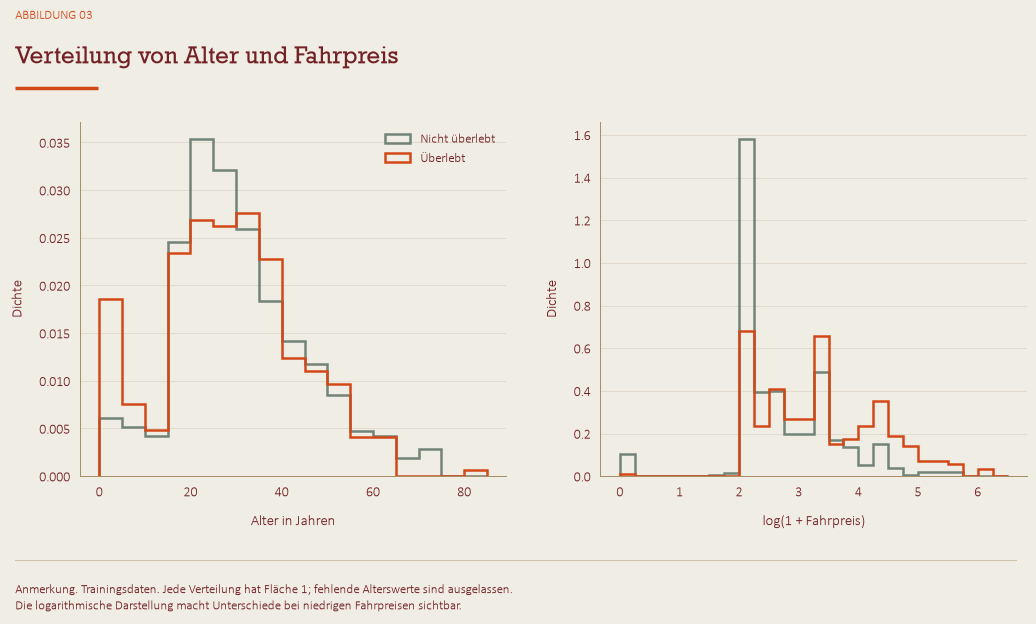

In [9]:
fig, achsen = plt.subplots(1, 2, figsize=(11, 6.5))
for ziel, farbe, text in [(0, SEKUNDAER, 'Nicht überlebt'), (1, PRIMAER, 'Überlebt')]:
    personen = analyse.loc[analyse.Survived == ziel]
    achsen[0].hist(personen.Age.dropna(), bins=np.arange(0, 86, 5), density=True, histtype='step', linewidth=1.8, color=farbe, label=text)
    achsen[1].hist(np.log1p(personen.Fare), bins=np.linspace(0, 6.5, 27), density=True, histtype='step', linewidth=1.8, color=farbe, label=text)
achsen[0].set(xlabel='Alter in Jahren', ylabel='Dichte')
achsen[1].set(xlabel='log(1 + Fahrpreis)', ylabel='Dichte')
achsen[0].legend(fontsize=9)
abbildung(fig, 3, 'Verteilung von Alter und Fahrpreis', 'Trainingsdaten. Jede Verteilung hat Fläche 1; fehlende Alterswerte sind ausgelassen.\nDie logarithmische Darstellung macht Unterschiede bei niedrigen Fahrpreisen sichtbar.', '03_alter_fahrpreis')



### Überleben einzelner Personen nach Familiengröße

Die Familiengröße wird für jede Person als `1 + SibSp + Parch` berechnet und in „Allein“, „2–4“ oder „5+“ eingeteilt. Jede Zeile zählt eine Person; `Survived` beschreibt ausschließlich ihr eigenes Überleben.

Die Quote ist **überlebende Personen / alle Personen in der Größenkategorie**. Die Kategorie „2–4“ umfasst also Personen aus vielen verschiedenen Familien. Es wird weder geprüft, ob mindestens ein Mitglied einer Familie überlebt hat, noch ob die gesamte Familie überlebt hat. `n` zählt Personen, nicht Familien.


,Überlebende Personen,Personen,Überlebensquote der Personen
Allein,163,537,0.304
2–4,169,292,0.579
5+,10,62,0.161


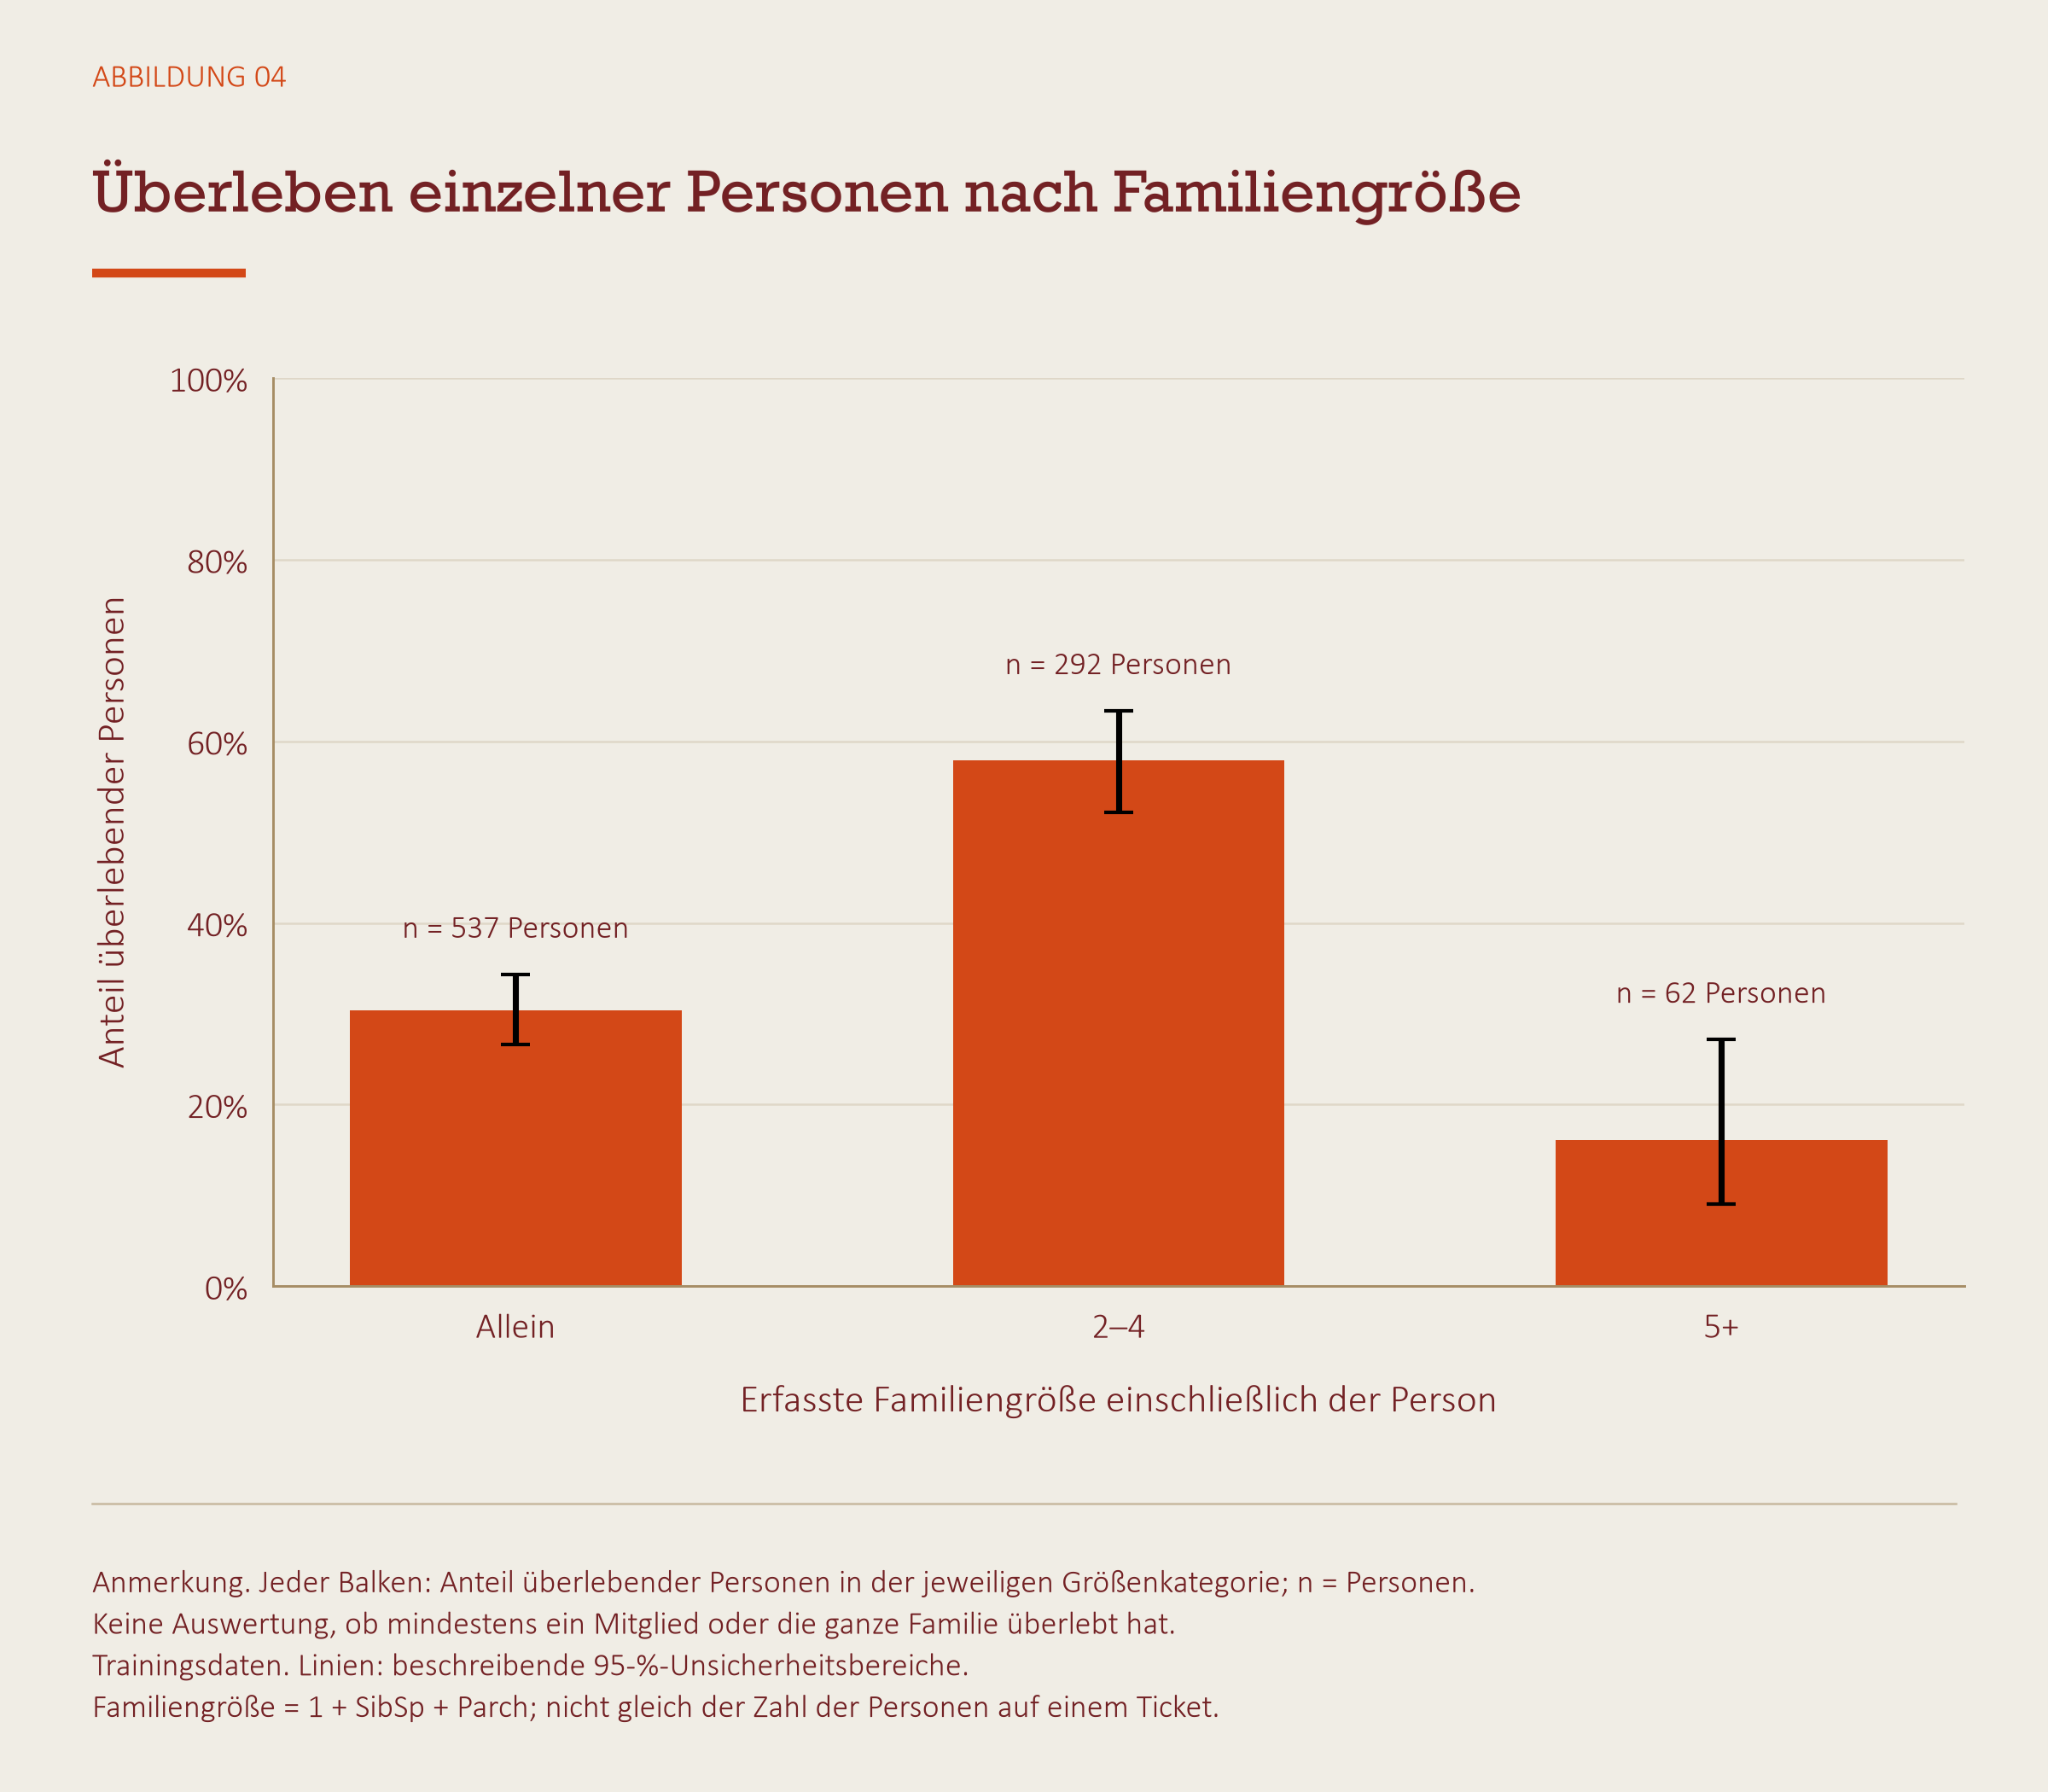

In [10]:
# Jede Zeile zählt eine Person; Survived beschreibt ihr eigenes Überleben.
familiengroesse = 1 + analyse.SibSp + analyse.Parch
familiengruppe = pd.cut(familiengroesse, [0, 1, 4, np.inf], labels=['Allein', '2–4', '5+'])
familienquoten = analyse.groupby(familiengruppe, observed=True).Survived.agg(['sum', 'count', 'mean'])
unten, oben = wilson_intervall(familienquoten['sum'], familienquoten['count'])
display(familienquoten.rename(columns={'sum': 'Überlebende Personen', 'count': 'Personen', 'mean': 'Überlebensquote der Personen'}))
fig, ax = plt.subplots(figsize=(8, 7))
ax.bar(familienquoten.index.astype(str), familienquoten['mean'], color=PRIMAER, width=0.55, yerr=[familienquoten['mean'] - unten, oben - familienquoten['mean']], capsize=4)
for position, (_, zeile) in enumerate(familienquoten.iterrows()):
    ax.text(position, oben.iloc[position] + 0.04, f"n = {int(zeile['count'])} Personen", ha='center', fontsize=9)
ax.set(xlabel='Erfasste Familiengröße einschließlich der Person', ylabel='Anteil überlebender Personen', ylim=(0, 1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
abbildung(fig, 4, 'Überleben einzelner Personen nach Familiengröße', 'Jeder Balken: Anteil überlebender Personen in der jeweiligen Größenkategorie; n = Personen.\nKeine Auswertung, ob mindestens ein Mitglied oder die ganze Familie überlebt hat.\nTrainingsdaten. Linien: beschreibende 95-%-Unsicherheitsbereiche.\nFamiliengröße = 1 + SibSp + Parch; nicht gleich der Zahl der Personen auf einem Ticket.', '04_familiengroesse')



## Welche Ideen prüfen wir weiter?

- Geschlecht, Alter und Ticketklasse bilden einen wichtigen Ausgangspunkt.
- Fehlendes Alter könnte selbst eine hilfreiche Information sein.
- Titel, Familiengröße und gemeinsame Tickets könnten weitere Hinweise geben.
- Die Kabinenangabe könnte mit den Überlebenschancen zusammenhängen.

In [Notebook 2](02_Feature_Engineering_und_Auswahl.ipynb) formulieren wir diese Ideen als zusätzliche Merkmale. Ob sie die Vorhersagen verbessern, prüfen wir in Notebook 3.


## Quellen

Daten: `train.csv` und `test.csv`. Aufgabenstellung: `Task_description.pdf`. Fachliche Grundlage: Lisa Grobelscheg, *Skriptum LV DSM, ITW 26/27* (`Skriptum.pdf`).

KI-Unterstützung wurde für Code, Abbildungen und Erklärungen verwendet.
